# Day 29 / 100 — ConveyorJam Watch | Training + Video Tracking Research

**Objective:** fine-tune a conveyor-domain YOLO detector on genuinely labeled image pairs, select by validation, assess held-out detection, then test YOLO + ByteTrack + a configurable dwell-time heuristic on real video and controlled sequences.

**Source of truth:** `/kaggle/input/datasets/loliwibu/conveyorjam-dataset`. Data originally supplied as separate Iron Ore, Supervisely, and reference-program sources. **No claimed real jam ground truth.** No automatic model-training success or fake detection accuracy. Missing labels are never silently treated as negatives. This notebook retains the original directory splits, refuses dangerous overlap, and exports reproducibility metadata.

**Execution:** Run All with GPU enabled and Internet on if Ultralytics / public weights require download. Kaggle's Save Version → Save & Run All is required to persist results. Default 2 training candidates, 20/15 epochs, image size 640, moderate bounded per-split samples; edit configuration to expand after successful audit. Video inference runs after training. If annotation structure violates contracts, stop and fix data rather than bypass gates.

## 00 — Dependencies, run configuration, provenance

In [1]:
import sys, os, subprocess, importlib.util, json, math, random, shutil, time, hashlib, warnings, re, gc
from pathlib import Path
from collections import Counter, defaultdict, deque
from datetime import datetime, timezone
from dataclasses import dataclass, field
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, FileLink
import cv2, torch, yaml
if importlib.util.find_spec('ultralytics') is None:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','ultralytics>=8.3,<9','lap>=0.5.12'])
import ultralytics
from ultralytics import YOLO

SEED=42
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
INPUT=Path('/kaggle/input/datasets/loliwibu/conveyorjam-dataset')
assert INPUT.is_dir(),f'Missing attached Kaggle dataset: {INPUT}'
WORK=Path('/kaggle/working/conveyorjam_day29_final')
OUT=WORK/'artifacts'; OUT.mkdir(parents=True,exist_ok=True)
VIDEO_OUT=OUT/'videos';VIDEO_OUT.mkdir(exist_ok=True)
STAGING=WORK/'yolo_training'
# Use all available annotated pairs by default; explicit caps may be set to protect GPU quota.
MAX_TRAIN_PAIRS=None; MAX_VAL_PAIRS=None
TRAIN_EPOCHS={'yolov8n':20,'yolov8s':15}
IMGSZ=640;BATCH=16;DEVICE=0 if torch.cuda.is_available() else 'cpu'
WORKERS=2;CONF=0.25;TRACKER='bytetrack.yaml'
MAX_VIDEOS=3;MAX_VIDEO_SECONDS=25;FRAME_STRIDE=3
DWELL_SECONDS=3.0;SPEED_PX_PER_SECOND=12.0;LOST_RESET_SECONDS=1.0
ROI_REL=(0.04,0.08,0.96,0.94)
print('Input:',INPUT,'CUDA:',torch.cuda.is_available())
print('Versions:',{'python':sys.version.split()[0],'torch':torch.__version__,'opencv':cv2.__version__,'ultralytics':ultralytics.__version__})

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Input: /kaggle/input/datasets/loliwibu/conveyorjam-dataset CUDA: True
Versions: {'python': '3.13.15', 'torch': '2.11.0+cu128', 'opencv': '4.14.0', 'ultralytics': '8.4.197'}


## 01 — Source discovery and legal/provenance boundaries
Iron Ore is the target detector domain; Supervisely video contains **man/bag** annotations (not jam events); the reference code is auxiliary. Verify source licenses before redistributing artifacts. The original split names do not prove video/session independence.

In [2]:
IRON=INPUT/'iron-ore'; TRACKING=INPUT/'tracking-video'; REFERENCE=INPUT/'tracking-reference'
assert IRON.is_dir() and TRACKING.is_dir(), 'Iron Ore and tracking sources must exist'
image_ext={'.jpg','.jpeg','.png','.webp'}
video_ext={'.mp4','.mov','.avi','.mkv','.webm'}
video_files=sorted(p for p in INPUT.rglob('*') if p.is_file() and p.suffix.lower() in video_ext and '__MACOSX' not in p.parts)
print('Video count:',len(video_files),'Iron Ore:',sum('iron-ore' in p.parts for p in video_files))
print('YOLO YAML:',[str(p.relative_to(IRON)) for p in IRON.rglob('*.yaml')][:20])
print('YOLO text labels:',len(list(IRON.rglob('*.txt'))))
provenance=[
 {'source':'Iron Ore Conveyor dataset','role':'detector training and industrial video','license':'NOT_VERIFIED','jam_labels':False},
 {'source':'Supervisely conveyor video','role':'tracking demonstration (man/bag)','license':'NOT_VERIFIED','jam_labels':False},
 {'source':'Camera-Based Conveyor Inspection Tracking','role':'reference code/output only','license':'NOT_VERIFIED','jam_labels':False}]
pd.DataFrame(provenance).to_csv(OUT/'source_provenance.csv',index=False)
assert video_files, 'No videos available'

Video count: 21 Iron Ore: 19
YOLO YAML: ['yolo-dataset-center/data.yaml']
YOLO text labels: 2474


## 02 — Discover actual YOLO train/val/test labels (do not train unlabeled frames)
Only paired images/annotation text files qualify for supervised training. Blank **existing** text files represent zero annotated boxes; missing text files do **not**. Multiple label roots, bad YOLO classes, inconsistent image stems, or missing validation/test must be investigated. Dataset metadata controls class names.

In [3]:
# Locate folder patterns train/images, train/labels, valid/images, valid/labels.
roots=[]
for images in IRON.rglob('images'):
    if not images.is_dir():continue
    split=images.parent.name.lower()
    if split not in ('train','valid','val','test'):continue
    labels=images.parent/'labels'
    if labels.is_dir():roots.append((images.parent.parent,split,images,labels))
print('Candidates:',[(str(r.relative_to(IRON)),s) for r,s,_,_ in roots])
byroot=defaultdict(dict)
for root,split,images,labels in roots:
    key='valid' if split=='val' else split
    byroot[root][key]=(images,labels)
complete=[(root,splits) for root,splits in byroot.items() if all(k in splits for k in ('train','valid','test'))]
assert complete,'No complete paired YOLO train/valid/test structure; inspect source archive manually'
# Prioritize center YOLO dataset (paired annotations), then maximal pair count.
def score(item):
    root,s=item
    count=sum(len(list(l.glob('*.txt'))) for im,l in s.values())
    return ('yolo-dataset-center' in str(root),count)
YOLO_ROOT, SPLIT_DIRS=sorted(complete,key=score,reverse=True)[0]
print('Selected YOLO root:',YOLO_ROOT)
print('Split directories:',{k:(str(v[0]),str(v[1])) for k,v in SPLIT_DIRS.items()})
config_files=list(YOLO_ROOT.glob('*.yaml'))+list(YOLO_ROOT.glob('*.yml'))
if not config_files:
    config_files=list(IRON.rglob('data.yaml'))
assert config_files,'Missing data.yaml: cannot safely identify model class mapping'
source_yaml=yaml.safe_load(config_files[0].read_text(encoding='utf-8-sig'))
print('Source yaml:',source_yaml)
names=source_yaml.get('names')
if isinstance(names,list): names={i:v for i,v in enumerate(names)}
if isinstance(names,dict):names={int(k):str(v) for k,v in names.items()}
assert isinstance(names,dict) and names and sorted(names)==list(range(len(names))), 'Class map invalid or missing'
NCLASS=len(names)
print('Class map:',names)

Candidates: [('yolo-dataset-center', 'valid'), ('yolo-dataset-center', 'test'), ('yolo-dataset-center', 'train')]
Selected YOLO root: /kaggle/input/datasets/loliwibu/conveyorjam-dataset/iron-ore/yolo-dataset-center
Split directories: {'valid': ('/kaggle/input/datasets/loliwibu/conveyorjam-dataset/iron-ore/yolo-dataset-center/valid/images', '/kaggle/input/datasets/loliwibu/conveyorjam-dataset/iron-ore/yolo-dataset-center/valid/labels'), 'test': ('/kaggle/input/datasets/loliwibu/conveyorjam-dataset/iron-ore/yolo-dataset-center/test/images', '/kaggle/input/datasets/loliwibu/conveyorjam-dataset/iron-ore/yolo-dataset-center/test/labels'), 'train': ('/kaggle/input/datasets/loliwibu/conveyorjam-dataset/iron-ore/yolo-dataset-center/train/images', '/kaggle/input/datasets/loliwibu/conveyorjam-dataset/iron-ore/yolo-dataset-center/train/labels')}
Source yaml: {'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 1, 'names': ['conveyor'], 'roboflow': {'workspace': '

## 03 — Full annotation integrity + coverage audit

In [4]:
rows=[];errors=[];orphan_labels=[]
for split,(images_dir,labels_dir) in SPLIT_DIRS.items():
    images=[p for p in images_dir.iterdir() if p.is_file() and p.suffix.lower() in image_ext]
    labels={p.stem:p for p in labels_dir.glob('*.txt')}
    image_stems=[p.stem for p in images]
    if len(image_stems)!=len(set(image_stems)):
        raise AssertionError(f'Ambiguous duplicate image stems: {split}')
    missing=set(image_stems)-set(labels)
    orphans=set(labels)-set(image_stems)
    orphan_labels.extend([{'split':split,'stem':k} for k in orphans])
    print(split,'images:',len(images),'labels:',len(labels),'unlabeled images:',len(missing),'orphan labels:',len(orphans))
    for p in sorted(images):
        if p.stem not in labels:continue
        lp=labels[p.stem];instances=0;issues=[]
        try:
            with Image.open(p) as im:
                W,H=im.size;im.verify()
                if min(W,H)<8:issues.append('tiny_image')
        except Exception as e:issues.append('bad_image:'+str(e)[:100])
        try:
            for line_no,line in enumerate(lp.read_text(encoding='utf-8-sig').splitlines(),1):
                if not line.strip():continue
                parts=line.split()
                if len(parts)!=5:issues.append(f'fields_{line_no}');continue
                vals=list(map(float,parts));cls,x,y,w,h=vals
                if not all(math.isfinite(v) for v in vals) or cls!=int(cls) or int(cls) not in names:issues.append(f'class_{line_no}');continue
                if not (0<=x<=1 and 0<=y<=1 and 0<w<=1 and 0<h<=1 and x-w/2>=-0.001 and x+w/2<=1.001 and y-h/2>=-0.001 and y+h/2<=1.001):issues.append(f'coord_{line_no}')
                instances+=1
        except Exception as e:issues.append('bad_label:'+str(e)[:100])
        rows.append({'split':split,'image':str(p),'label':str(lp),'instances':instances,'positive':instances>0})
        if issues:errors.append({'split':split,'image':str(p),'issues':';'.join(issues)})
manifest=pd.DataFrame(rows)
assert not manifest.empty, 'No paired image labels discovered'
summary=manifest.groupby('split').agg(pairs=('image','size'),positives=('positive','sum'),boxes=('instances','sum')).reset_index()
summary['negatives']=summary.pairs-summary.positives
display(summary)
summary.to_csv(OUT/'dataset_inventory.csv',index=False)
pd.DataFrame(errors,columns=['split','image','issues']).to_csv(OUT/'annotation_errors.csv',index=False)
pd.DataFrame(orphan_labels,columns=['split','stem']).to_csv(OUT/'orphan_labels.csv',index=False)
if errors:raise RuntimeError(f'{len(errors)} invalid paired annotations. Correct before training.')
assert set(summary.split)=={'train','valid','test'} and all(summary.pairs>0),'Insufficient split coverage'
assert manifest.instances.sum()>0, 'No labeled boxes at all'
print('Annotation geometry: PASS. Unpaired images EXCLUDED from supervised experiments.')

valid images: 96 labels: 96 unlabeled images: 0 orphan labels: 0
test images: 95 labels: 95 unlabeled images: 0 orphan labels: 0
train images: 2283 labels: 2283 unlabeled images: 0 orphan labels: 0


,split,pairs,positives,boxes,negatives
0,test,95,95,95,0
1,train,2283,2283,2283,0
2,valid,96,96,96,0


Annotation geometry: PASS. Unpaired images EXCLUDED from supervised experiments.


## 04 — Exact leakage check (image hashes and semantic same-file risk)

In [5]:
def sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''):h.update(chunk)
    return h.hexdigest()
hash_groups=defaultdict(list)
for row in manifest.itertuples(index=False):
    hash_groups[sha(row.image)].append((row.split,row.image))
leaks=[v for v in hash_groups.values() if len({s for s,_ in v})>1]
(OUT/'sha_cross_split_audit.json').write_text(json.dumps({'cross_split_groups':len(leaks),'examples':leaks[:25]},indent=2))
print('Exact cross-split duplicate groups:',len(leaks))
if leaks:raise RuntimeError('STOP: exact image cross-split leakage; correct source split before training')
# Source filenames with Roboflow .rf.* may represent augmentations of the same original frame.
def stem_origin(path):
    name=Path(path).stem
    name=re.sub(r'\.rf\.[0-9a-f]+$','',name)
    return name.lower()
origin=defaultdict(set)
for row in manifest.itertuples(index=False): origin[stem_origin(row.image)].add(row.split)
origin_leaks=[k for k,v in origin.items() if len(v)>1]
(OUT/'original_stem_overlap.json').write_text(json.dumps({'cross_split_origin_stem_count':len(origin_leaks),'examples':origin_leaks[:40]},indent=2))
print('Potential same-source filename overlap:',len(origin_leaks))
if origin_leaks:
    print('WARNING: near-duplicates or augmented source frames may cross splits. See original_stem_overlap.json. Held-out metrics cannot be described as independence-verified.')
print('Exact hash audit PASS; perceptual and video-source independence remain unverified.')

Exact cross-split duplicate groups: 0
Potential same-source filename overlap: 0
Exact hash audit PASS; perceptual and video-source independence remain unverified.


## 05 — Build bounded and deterministic YOLO input manifests
Keep original split assignments. Only annotated pairs enter supervised training. Dataset labels are not rewritten; symlinks used where possible. If copied, data are byte identical.

In [6]:
def sample_part(split,limit):
    part=manifest[manifest.split==split].copy()
    if limit is not None and len(part)>limit:part=part.sample(n=limit,random_state=SEED).sort_values('image')
    return part
selected={s:sample_part(s,{'train':MAX_TRAIN_PAIRS,'valid':MAX_VAL_PAIRS,'test':None}[s]) for s in ('train','valid','test')}
for split,frame in selected.items():
    frame.to_csv(OUT/f'{split}_pairs_manifest.csv',index=False)
    print(split,len(frame),'boxes:',int(frame.instances.sum()))
    for row in frame.itertuples(index=False):
        for kind,src in [('images',Path(row.image)),('labels',Path(row.label))]:
            target=STAGING/split/kind/src.name
            target.parent.mkdir(parents=True,exist_ok=True)
            if target.exists() or target.is_symlink():continue
            try:target.symlink_to(src)
            except OSError:shutil.copy2(src,target)
YOLO_CONFIG=WORK/'boxcount_data.yaml'
YOLO_CONFIG.write_text(yaml.safe_dump({'path':str(STAGING),'train':'train/images','val':'valid/images','test':'test/images','names':names,'nc':NCLASS},sort_keys=False))
print('Training YAML:',YOLO_CONFIG)
assert all(any((STAGING/s/'images').iterdir()) for s in ('train','valid','test'))

train 2283 boxes: 2283
valid 96 boxes: 96
test 95 boxes: 95
Training YAML: /kaggle/working/conveyorjam_day29_final/boxcount_data.yaml


## 06 — Visual annotation QA samples

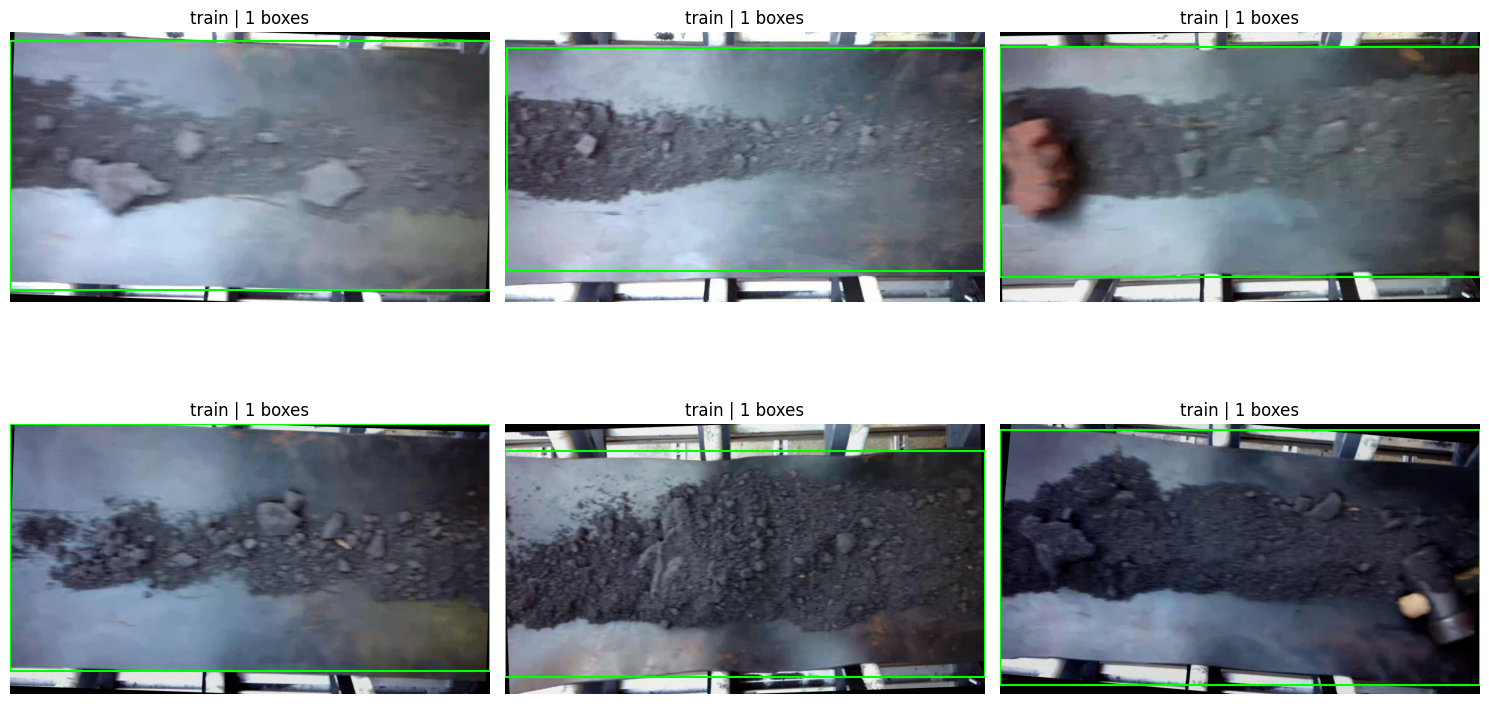

In [7]:
from matplotlib.patches import Rectangle
fig,axes=plt.subplots(2,3,figsize=(15,9))
for ax,row in zip(axes.ravel(),manifest[manifest.instances>0].sample(n=min(6,int((manifest.instances>0).sum())),random_state=SEED).itertuples(index=False)):
    with Image.open(row.image) as im: pic=im.convert('RGB')
    ax.imshow(pic);w,h=pic.size
    for line in Path(row.label).read_text(encoding='utf-8-sig').splitlines():
        if not line.strip():continue
        cl,x,y,bw,bh=map(float,line.split())
        ax.add_patch(Rectangle(((x-bw/2)*w,(y-bh/2)*h),bw*w,bh*h,edgecolor='lime',facecolor='none',lw=1.5))
    ax.set_title(f'{row.split} | {row.instances} boxes');ax.axis('off')
for ax in axes.ravel()[min(6,int((manifest.instances>0).sum())):]:ax.axis('off')
fig.tight_layout();fig.savefig(OUT/'annotation_gallery.png',dpi=140);plt.show()

## 07 — Fine-tune YOLOv8n and YOLOv8s (no test-based selection)
Each candidate is trained solely on original training samples and internal validation; early-stopping / best checkpoint selection uses validation only. Pretrained initialization is explicitly documented. Candidate count and duration affect reproducibility and compute. Kaggle GPU resources may differ.

In [8]:
train_results=[];trained_paths={}
for model_name,epochs in TRAIN_EPOCHS.items():
    print('TRAINING:',model_name,'epochs:',epochs)
    model=YOLO(model_name+'.pt')
    result=model.train(data=str(YOLO_CONFIG),epochs=epochs,imgsz=IMGSZ,batch=BATCH,device=DEVICE,seed=SEED,workers=WORKERS,patience=7,project=str(WORK/'runs'),name=model_name,exist_ok=True,plots=True,verbose=True)
    best=Path(model.trainer.best)
    assert best.is_file(),f'Trained best.pt missing: {model_name}'
    trained_paths[model_name]=best
    train_results.append({'experiment':model_name,'epochs_requested':epochs,'best_path':str(best),'best_bytes':best.stat().st_size})
    del model;gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
pd.DataFrame(train_results).to_csv(OUT/'training_experiments.csv',index=False)
assert trained_paths,'No completed training candidates'
print('Trained candidates:',list(trained_paths))

TRAINING: yolov8n epochs: 20
Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/conveyorjam_day29_final/boxcount_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yo

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/20      2.07G     0.3573     0.2982     0.9622         33        640: 100% ━━━━━━━━━━━━ 143/143 8.1it/s 17.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 6.6it/s 0.5s
                   all         96         96      0.998          1      0.995      0.927

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/20      2.07G     0.3521     0.2832     0.9553         35        640: 100% ━━━━━━━━━━━━ 143/143 7.9it/s 18.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 6.4it/s 0.5s
                   all         96         96      0.997          1      0.995       0.97

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/20      2.07G     0.3284     0.2585     0.9436         30        640: 100% ━━━━━━━━━━━━ 143/143 7.9it/s 18.2s
                 Class     Images  Instances      Box(P  

## 08 — Validation-only champion selection
All candidates are evaluated on the **same** validation subset. Select by mAP@50:95; test set is untouched until next section. Champion best.pt is copied after validation.

In [9]:
validation=[]
for name,path in trained_paths.items():
    model=YOLO(str(path))
    v=model.val(data=str(YOLO_CONFIG),split='val',device=DEVICE,imgsz=IMGSZ,batch=BATCH,plots=False,verbose=False)
    validation.append({'model':name,'path':str(path),'val_mAP50_95':float(v.box.map),'val_mAP50':float(v.box.map50),'val_precision':float(v.box.mp),'val_recall':float(v.box.mr)})
    del model;gc.collect()
val_df=pd.DataFrame(validation).sort_values(['val_mAP50_95','val_mAP50'],ascending=False)
val_df.to_csv(OUT/'validation_selection.csv',index=False)
display(val_df)
CHAMPION=val_df.iloc[0]['model']; CHAMPION_PATH=Path(val_df.iloc[0]['path'])
shutil.copy2(CHAMPION_PATH,OUT/'conveyorjam_champion.pt')
print('CHAMPION selected ONLY on validation:',CHAMPION)

Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 94.7±42.7 MB/s, size: 77.8 KB)
val: Scanning /kaggle/working/conveyorjam_day29_final/yolo_training/valid/labels.cache... 96 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 96/96 31.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 7.9it/s 0.8s
                   all         96         96      0.999          1      0.995       0.99
Speed: 0.5ms preprocess, 2.9ms inference, 0.0ms loss, 0.8ms postprocess per image
Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 117.2±7.7 MB/s, size: 64.1 KB)
val: Scanning /kaggle/working/conveyorjam_day2

,model,path,val_mAP50_95,val_mAP50,val_precision,val_recall
1,yolov8s,/kaggle/working/conveyorjam_day29_final/runs/y...,0.990524,0.995,0.999450,1.0
0,yolov8n,/kaggle/working/conveyorjam_day29_final/runs/y...,0.989531,0.995,0.999442,1.0


CHAMPION selected ONLY on validation: yolov8s


## 09 — Final held-out detection evaluation
No further tuning using test scores. Detection metrics are for this source and original test partition, not for actual jam events. Original source/video grouping and near-duplicates require separate confirmation before claiming external generalization.

In [10]:
detector=YOLO(str(CHAMPION_PATH))
test_eval=detector.val(data=str(YOLO_CONFIG),split='test',device=DEVICE,imgsz=IMGSZ,batch=BATCH,plots=False,verbose=False)
heldout={'champion':CHAMPION,'test_images':len(selected['test']),'mAP50':float(test_eval.box.map50),'mAP50_95':float(test_eval.box.map),'precision':float(test_eval.box.mp),'recall':float(test_eval.box.mr),'source':'Iron Ore YOLO labeled source test','cross_video_independence_verified':False}
(OUT/'heldout_detection.json').write_text(json.dumps(heldout,indent=2))
display(pd.DataFrame([heldout]))
print('Test consulted only after validation selection.')

Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 127.2±57.9 MB/s, size: 75.1 KB)
val: Scanning /kaggle/working/conveyorjam_day29_final/yolo_training/test/labels... 95 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 95/95 1.1Kit/s 0.1s
val: New cache created: /kaggle/working/conveyorjam_day29_final/yolo_training/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 6.4it/s 0.9s
                   all         95         95          1          1      0.995      0.985
Speed: 0.5ms preprocess, 4.8ms inference, 0.0ms loss, 0.8ms postprocess per image


,champion,test_images,mAP50,mAP50_95,precision,recall,source,cross_video_independence_verified
0,yolov8s,95,0.995,0.984765,1.0,1.0,Iron Ore YOLO labeled source test,False


Test consulted only after validation selection.


## 10 — Video inventory + video-source selection
The Iron Ore champion applies only to its source classes; tracking-video uses COCO people/bags. The public tracking video is not jam event ground truth. Choose one tracking video and up to two Iron Ore videos; processing limits are explicit.

In [11]:
vid=[]
for p in video_files:
    cap=cv2.VideoCapture(str(p));ok=cap.isOpened();fps=float(cap.get(cv2.CAP_PROP_FPS)) if ok else 0
    nf=int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) if ok else 0
    w=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)) if ok else 0;h=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)) if ok else 0
    ret,_=cap.read() if ok else (False,None);cap.release()
    source='iron' if 'iron-ore' in p.parts else 'tracking' if 'tracking-video' in p.parts else 'reference'
    vid.append({'source':source,'name':p.name,'path':str(p),'fps':fps,'duration_s':nf/fps if fps else None,'width':w,'height':h,'readable':bool(ret),'frame_count':nf})
vid_df=pd.DataFrame(vid);vid_df.to_csv(OUT/'video_inventory.csv',index=False)
display(vid_df.drop(columns=['path']).head(25))
ready=vid_df[vid_df.readable & (vid_df.fps>0)]
sel=pd.concat([ready[ready.source=='tracking'].sort_values('name').head(1),ready[ready.source=='iron'].sort_values('name').head(max(0,MAX_VIDEOS-1))]).head(MAX_VIDEOS)
assert not sel.empty
sel.to_csv(OUT/'selected_videos.csv',index=False)
display(sel[['source','name','fps','duration_s']])

,source,name,fps,duration_s,width,height,readable,frame_count
0,iron,boardcamera_iron_ore.mp4,117.631634,249.159167,1280,720,True,29309
1,iron,boardcamera_iron_ore_2.mp4,119.689445,35.742500,1280,720,True,4278
2,iron,boardcamera_iron_ore_3.mp4,119.221066,58.169250,1280,720,True,6935
3,iron,boardcamera_iron_ore_4.mp4,119.317422,41.108833,1280,720,True,4905
4,iron,boardcamera_iron_ore_5.mp4,119.581020,119.743083,1280,720,True,14319
5,iron,boardcamera_iron_ore_6.mp4,119.615266,86.527417,1280,720,True,10350
6,iron,boardcamera_iron_ore_7_wood.mp4,119.423387,36.090083,1280,720,True,4310
7,iron,boardcamera_iron_ore_7_wood_2.mp4,119.182880,36.188083,1280,720,True,4313
8,iron,boardcamera_iron_ore_7_wood_3.mp4,117.810835,33.163333,1280,720,True,3907
9,iron,boardcamera_iron_ore_canga.mp4,119.208252,25.778417,1280,720,True,3073


,source,name,fps,duration_s
20,tracking,conveyor.mp4,60.000000,26.366667
0,iron,boardcamera_iron_ore.mp4,117.631634,249.159167
1,iron,boardcamera_iron_ore_2.mp4,119.689445,35.742500


## 11 — Dwell-time state machine and controlled algorithm tests
Dwell measured in source-video seconds; no wall-clock approximation. Stationary threshold is in pixels/sec and should be calibrated for each camera. Events are heuristic. Simulated ID trajectories test algorithm logic, **not** actual detector quality.

In [12]:
@dataclass
class TrackState:
    xy:tuple
    time_s:float
    stationary_since:float|None=None
    speeds:deque=field(default_factory=lambda:deque(maxlen=5))
    obs:int=1
    alerted:bool=False
    alert_start:float|None=None
class DwellMonitor:
    def __init__(self,threshold=3.,max_speed=12.,max_gap=1.,roi=(0,0,1,1),min_obs=3):
        self.threshold=threshold;self.max_speed=max_speed;self.max_gap=max_gap;self.roi=roi;self.min_obs=min_obs;self.states={};self.events=[]
    def close(self,tid,t,reason):
        st=self.states.get(tid)
        if st and st.alerted:
            self.events.append({'track_id':tid,'start_s':st.alert_start,'end_s':t,'reason':reason})
            st.alerted=False;st.alert_start=None
    def update(self,points,t,w,h):
        seen=set();out=[]
        for tid,cx,cy,cls,score in points:
            if tid is None:continue
            tid=int(tid);xy=(float(cx),float(cy));seen.add(tid)
            x1,y1,x2,y2=self.roi
            if not(x1*w<=cx<=x2*w and y1*h<=cy<=y2*h):
                self.close(tid,t,'left_roi');self.states.pop(tid,None);continue
            st=self.states.get(tid)
            if st is None or t-st.time_s>self.max_gap:
                if st:self.close(tid,st.time_s,'gap')
                self.states[tid]=TrackState(xy,t)
                out.append({'id':tid,'dwell':0.,'alert':False});continue
            dt=t-st.time_s
            speed=math.dist(xy,st.xy)/dt if dt>1e-6 else float('inf')
            st.speeds.append(speed);st.obs+=1
            stationary=st.obs>=self.min_obs and np.median(st.speeds)<=self.max_speed
            if stationary:
                if st.stationary_since is None:st.stationary_since=t
                dwell=t-st.stationary_since
                if dwell>=self.threshold and not st.alerted:
                    st.alerted=True;st.alert_start=t
            else:
                self.close(tid,t,'movement');st.stationary_since=None;dwell=0.
            st.xy=xy;st.time_s=t
            out.append({'id':tid,'dwell':round(dwell,3),'alert':st.alerted})
        for tid,st in list(self.states.items()):
            if tid not in seen and t-st.time_s>self.max_gap:
                self.close(tid,st.time_s,'lost');self.states.pop(tid,None)
        return out
    def finish(self,t):
        for tid in list(self.states):self.close(tid,t,'video_end')

def simulate(name,fn,seconds=10,fps=10):
    m=DwellMonitor(threshold=DWELL_SECONDS,max_speed=8.,roi=(0,0,1,1),min_obs=3)
    flags=[]
    for i in range(int(seconds*fps)):
        t=i/fps;states=m.update([(1,fn(t),100,0,1.)],t,640,360)
        flags.append(states[0]['alert'])
    m.finish(seconds)
    return any(flags),len(m.events)
scenarios={'moving':(lambda t:20+35*t,False),'brief_stop':(lambda t:20+35*min(t,2)+35*max(0,t-3.5),False),'long_stop':(lambda t:20+35*min(t,2)+35*max(0,t-7),True)}
unit=[]
for name,(fn,expected) in scenarios.items():
    actual,n=simulate(name,fn)
    unit.append({'scenario':name,'expected_alert':expected,'observed_alert':actual,'events':n,'passed':expected==actual})
df_unit=pd.DataFrame(unit);display(df_unit)
df_unit.to_csv(OUT/'dwell_unit_tests.csv',index=False)
assert df_unit.passed.all(),'Dwell algorithm tests failed'

,scenario,expected_alert,observed_alert,events,passed
0,moving,False,False,0,True
1,brief_stop,False,False,0,True
2,long_stop,True,True,1,True


## 12 — Video YOLO + ByteTrack using the trained model
Each video starts a fresh tracker. Only videos from Iron Ore use the new trained model. Frames are processed chronologically. Output videos are illustrations; zero alerts cannot establish real absence of jams.

In [13]:
def process_video(item):
    path=Path(item.path);source=item.source;fps=float(item.fps)
    model=YOLO(str(CHAMPION_PATH) if source=='iron' else 'yolov8n.pt')
    cap=cv2.VideoCapture(str(path))
    assert cap.isOpened()
    w=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH));h=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    limit=min(int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),int(fps*MAX_VIDEO_SECONDS))
    output=VIDEO_OUT/f'{source}_{re.sub("[^A-Za-z0-9_-]","_",path.stem)}_annotated.mp4'
    writer=cv2.VideoWriter(str(output),cv2.VideoWriter_fourcc(*'mp4v'),max(1.,fps/FRAME_STRIDE),(w,h))
    assert writer.isOpened(),'MP4 writer failed'
    monitor=DwellMonitor(threshold=DWELL_SECONDS,max_speed=SPEED_PX_PER_SECOND,max_gap=LOST_RESET_SECONDS,roi=ROI_REL)
    events=[];timeline=[];seen=0;start=time.perf_counter()
    try:
        for idx in range(limit):
            ok,frame=cap.read()
            if not ok:break
            if idx%FRAME_STRIDE:continue
            seen+=1;t=idx/fps
            pred=model.track(frame,tracker=TRACKER,persist=True,conf=CONF,imgsz=IMGSZ,device=DEVICE,verbose=False)[0]
            obs=[];boxes=[]
            if pred.boxes is not None and pred.boxes.id is not None:
                for box,tid in zip(pred.boxes,pred.boxes.id.cpu().tolist()):
                    xyxy=box.xyxy[0].cpu().tolist();cx=(xyxy[0]+xyxy[2])/2;cy=(xyxy[1]+xyxy[3])/2
                    cls=int(box.cls[0]);cf=float(box.conf[0]);obs.append((int(tid),cx,cy,cls,cf));boxes.append((int(tid),xyxy,cls,cf))
            states=monitor.update(obs,t,w,h);lookup={s['id']:s for s in states}
            x1,y1,x2,y2=ROI_REL
            cv2.rectangle(frame,(int(x1*w),int(y1*h)),(int(x2*w),int(y2*h)),(180,200,60),2)
            for tid,box,cls,cf in boxes:
                st=lookup.get(tid,{});alert=st.get('alert',False);clr=(0,0,255) if alert else (40,175,70)
                a,b,c,d=map(int,box);cv2.rectangle(frame,(a,b),(c,d),clr,2)
                cv2.putText(frame,f'ID {tid} {model.names[cls]} dwell {st.get("dwell",0):.1f}s'+(' JAM?' if alert else ''),(a,max(20,b-7)),cv2.FONT_HERSHEY_SIMPLEX,.5,clr,2)
            active=sum(s['alert'] for s in states)
            cv2.putText(frame,f'{t:.2f}s  tracking={len(boxes)}  alerts={active}',(12,32),cv2.FONT_HERSHEY_SIMPLEX,.8,(255,255,255),2)
            writer.write(frame)
            timeline.append({'video':output.name,'source':source,'video_time_s':t,'tracked':len(boxes),'alerts':active})
    finally:
        writer.release();cap.release()
    monitor.finish(limit/fps)
    events=[{'video':output.name,'source':source,**v} for v in monitor.events]
    elapsed=time.perf_counter()-start
    return {'video':output.name,'source':source,'frames_processed':seen,'processing_fps':seen/max(elapsed,1e-9),'potential_alerts':len(events),'detector':'fine_tuned_iron_ore' if source=='iron' else 'pretrained_coco'},timeline,events
results=[];timeline=[];alerts=[]
for item in sel.itertuples(index=False):
    print('Running',item.name,'source',item.source)
    r,tl,al=process_video(item)
    results.append(r);timeline+=tl;alerts+=al
    print(r)
pd.DataFrame(results).to_csv(OUT/'video_processing_summary.csv',index=False)
pd.DataFrame(timeline).to_csv(OUT/'video_timeline.csv',index=False)
pd.DataFrame(alerts,columns=['video','source','track_id','start_s','end_s','reason']).to_csv(OUT/'potential_jam_events_UNVERIFIED.csv',index=False)
display(pd.DataFrame(results))

Running conveyor.mp4 source tracking
{'video': 'tracking_conveyor_annotated.mp4', 'source': 'tracking', 'frames_processed': 500, 'processing_fps': 25.258655381481823, 'potential_alerts': 0, 'detector': 'pretrained_coco'}
Running boardcamera_iron_ore.mp4 source iron
{'video': 'iron_boardcamera_iron_ore_annotated.mp4', 'source': 'iron', 'frames_processed': 980, 'processing_fps': 43.454644039757966, 'potential_alerts': 1, 'detector': 'fine_tuned_iron_ore'}
Running boardcamera_iron_ore_2.mp4 source iron
{'video': 'iron_boardcamera_iron_ore_2_annotated.mp4', 'source': 'iron', 'frames_processed': 998, 'processing_fps': 41.87702968359081, 'potential_alerts': 1, 'detector': 'fine_tuned_iron_ore'}


,video,source,frames_processed,processing_fps,potential_alerts,detector
0,tracking_conveyor_annotated.mp4,tracking,500,25.258655,0,pretrained_coco
1,iron_boardcamera_iron_ore_annotated.mp4,iron,980,43.454644,1,fine_tuned_iron_ore
2,iron_boardcamera_iron_ore_2_annotated.mp4,iron,998,41.877030,1,fine_tuned_iron_ore


## 13 — Evidence: video frame snapshots, charts, downloadable video links

iron_boardcamera_iron_ore_2_annotated.mp4 MiB 28.73


/kaggle/working/conveyorjam_day29_final/artifacts/videos/iron_boardcamera_iron_ore_2_annotated.mp4

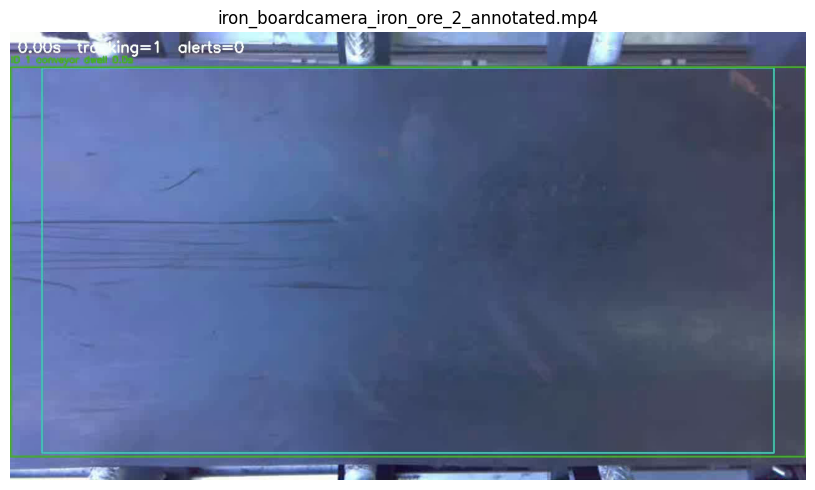

iron_boardcamera_iron_ore_annotated.mp4 MiB 20.31


/kaggle/working/conveyorjam_day29_final/artifacts/videos/iron_boardcamera_iron_ore_annotated.mp4

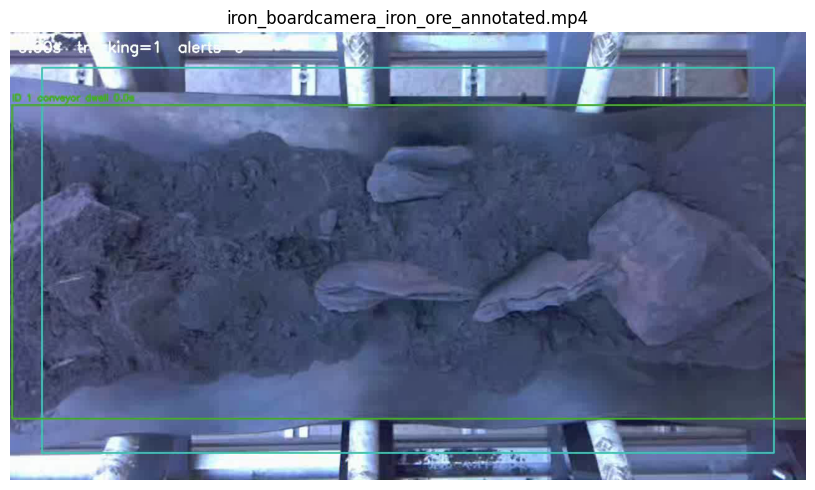

tracking_conveyor_annotated.mp4 MiB 29.42


/kaggle/working/conveyorjam_day29_final/artifacts/videos/tracking_conveyor_annotated.mp4

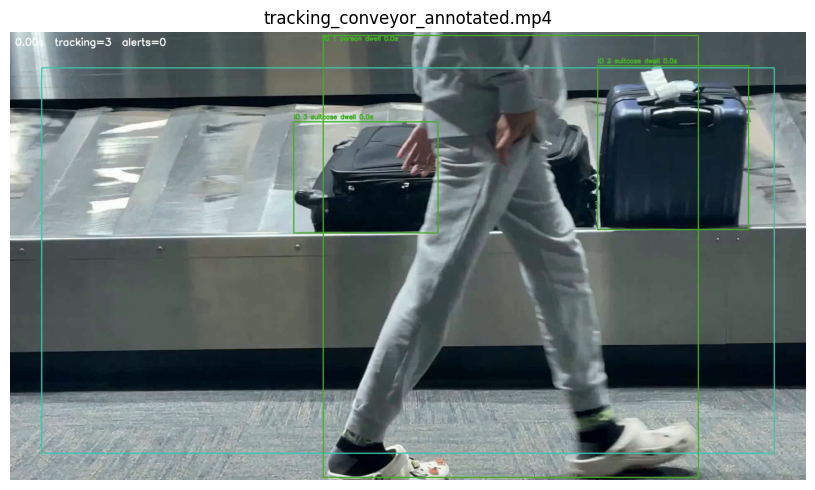

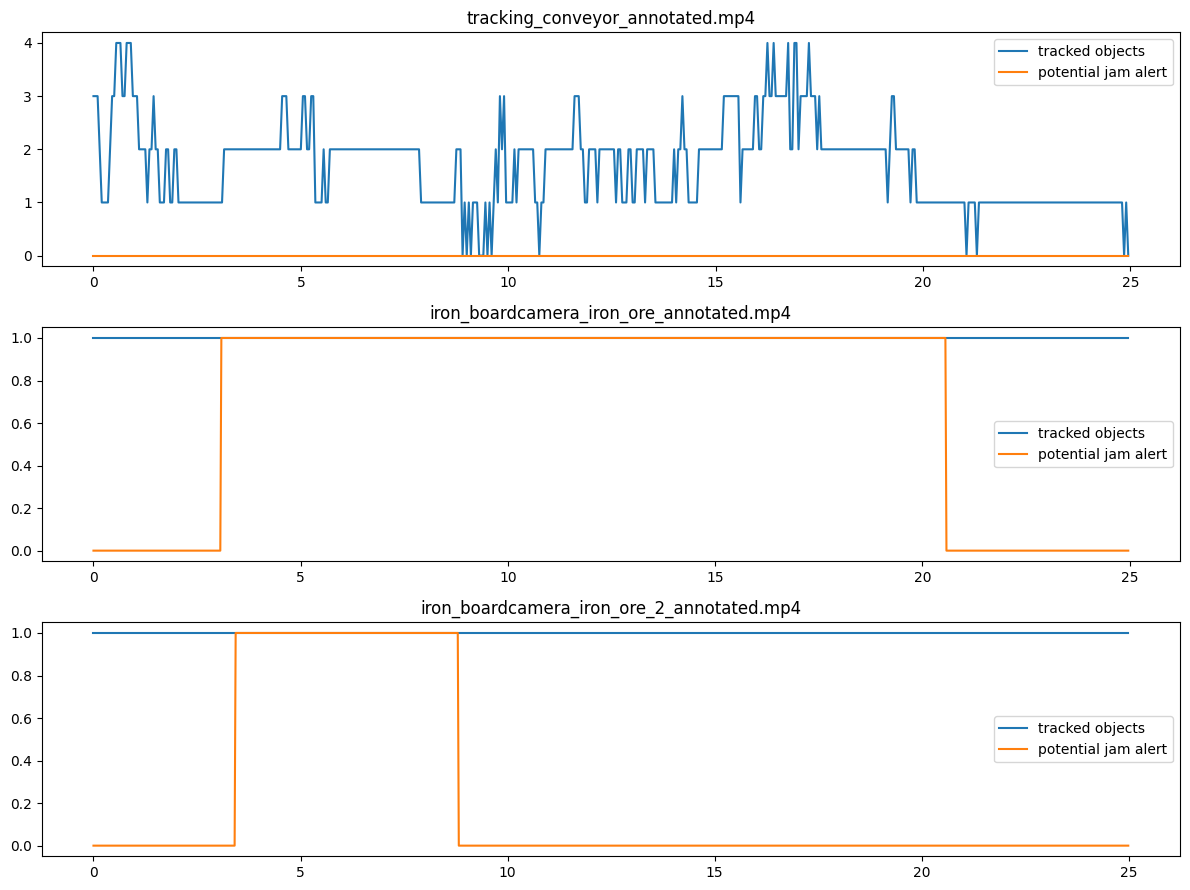

In [14]:
for p in sorted(VIDEO_OUT.glob('*.mp4')):
    print(p.name,'MiB',round(p.stat().st_size/2**20,2));display(FileLink(str(p)))
    cap=cv2.VideoCapture(str(p));ok,frame=cap.read();cap.release()
    if ok:
        fig,ax=plt.subplots(figsize=(10,5));ax.imshow(cv2.cvtColor(frame,cv2.COLOR_BGR2RGB));ax.set_title(p.name);ax.axis('off');fig.tight_layout();fig.savefig(OUT/f'{p.stem}_preview.png',dpi=130);plt.show()
if timeline:
    df_tl=pd.DataFrame(timeline)
    fig,axs=plt.subplots(len(results),1,figsize=(12,max(3,3*len(results))),squeeze=False)
    for ax,(name,g) in zip(axs[:,0],df_tl.groupby('video',sort=False)):
        ax.plot(g.video_time_s,g.tracked,label='tracked objects');ax.plot(g.video_time_s,g.alerts,label='potential jam alert');ax.set_title(name);ax.legend()
    fig.tight_layout();fig.savefig(OUT/'video_alert_timeline.png',dpi=140);plt.show()

## 14 — Scientific research report, reproducibility, claim boundaries

In [15]:
report={
 'project':'ConveyorJam Watch — Day 29/100','timestamp_utc':datetime.now(timezone.utc).isoformat(),
 'dataset_root':str(INPUT),'training_root':str(YOLO_ROOT),'source_yaml':str(config_files[0]),
 'class_names':names,'seed':SEED,'split':'source-provided train/valid/test; held-out test not used for selection',
 'source_pair_counts':summary.to_dict('records'),'sampled_training_counts':{k:len(v) for k,v in selected.items()},
 'exact_cross_split_sha_groups':len(leaks),'possible_same_origin_name_groups':len(origin_leaks),
 'models_trained':train_results,'selection_metric':'validation mAP50:95','validation_candidates':validation,
 'champion':CHAMPION,'heldout_detection':heldout,
 'dwell_tests':unit,'video_demo':results,'potential_jam_events':len(alerts),
 'verified_real_jam_labels':False,'real_jam_precision_recall_f1':None,
 'limitations':['No real conveyor-jam event ground truth','Image-source near duplicates and source-video independence unverified','YOLO domain detection is not equivalent to jam detection','Dwell px/s threshold not calibrated to physical speed','Tracker ID switches and camera motion can invalidate dwell','COCO tracking video domain has different classes','Source licenses require verification before publishing or distributing','No live control, industrial safety or production validation'],
 'deployment_ready':False}
(OUT/'research_report.json').write_text(json.dumps(report,indent=2,default=str))
(OUT/'environment.json').write_text(json.dumps({'python':sys.version,'torch':torch.__version__,'opencv':cv2.__version__,'ultralytics':ultralytics.__version__,'cuda':torch.cuda.get_device_name(0) if torch.cuda.is_available() else None},indent=2))
(OUT/'claim_boundaries.json').write_text(json.dumps(report['limitations'],indent=2))
print('Research report written. Held-out detection is not real jam accuracy.')

Research report written. Held-out detection is not real jam accuracy.


## 15 — Manifest & final ZIP (model + evidence, no copyrighted raw data)

In [16]:
from zipfile import ZipFile
(OUT/'README.md').write_text("""# ConveyorJam Day29 — Authentic executed research artifacts

Includes trained champion YOLO weights, validation selection, held-out detection metrics, audit records, video demonstration, and dwell-time unit tests. Real jam event labels were unavailable: any alerts are unverified heuristic signals. Before redistribution of derived videos, verify each original dataset's licensing. No industrial safety/deployment claim.
""")
archive=shutil.make_archive(str(WORK/'ConveyorJam_Day29_FINAL_Research_Results'),'zip',root_dir=OUT)
with ZipFile(archive) as z:
    bad=z.testzip()
    assert bad is None,f'CRC error: {bad}'
    print('ZIP entries:',len(z.infolist()))
print('ZIP:',archive,'MiB:',round(Path(archive).stat().st_size/2**20,2),'CRC PASS')
print('Artifact listing:')
for p in sorted(OUT.rglob('*')):
    if p.is_file(): print(p.relative_to(OUT))

ZIP entries: 32
ZIP: /kaggle/working/conveyorjam_day29_final/ConveyorJam_Day29_FINAL_Research_Results.zip MiB: 98.0 CRC PASS
Artifact listing:
README.md
annotation_errors.csv
annotation_gallery.png
claim_boundaries.json
conveyorjam_champion.pt
dataset_inventory.csv
dwell_unit_tests.csv
environment.json
heldout_detection.json
iron_boardcamera_iron_ore_2_annotated_preview.png
iron_boardcamera_iron_ore_annotated_preview.png
original_stem_overlap.json
orphan_labels.csv
potential_jam_events_UNVERIFIED.csv
research_report.json
selected_videos.csv
sha_cross_split_audit.json
source_provenance.csv
test_pairs_manifest.csv
tracking_conveyor_annotated_preview.png
train_pairs_manifest.csv
training_experiments.csv
valid_pairs_manifest.csv
validation_selection.csv
video_alert_timeline.png
video_inventory.csv
video_processing_summary.csv
video_timeline.csv
videos/iron_boardcamera_iron_ore_2_annotated.mp4
videos/iron_boardcamera_iron_ore_annotated.mp4
videos/tracking_conveyor_annotated.mp4


## 16 — Before · Now · Next / Final scientific checklist

**Before:** original Iron Ore image corpus, 19 raw industrial videos, Supervisely man/bag tracking annotations, independent reference project. Prior two notebooks only ran pretrained COCO detection on three clips and did not train any image detector.

**Now:** explicit annotation audit; train/valid/test source split; image SHA-256 audit; possible source name overlap warning; two actual YOLO fine-tuning candidates; validation-only champion choice; held-out detection report; source-specific ByteTrack and dwell alerts; controlled three-scenario logic checks; evidence videos; manifests + ZIP.

**Next:** verify image grouping by original video and perceptual near duplicates; obtain real incident-labeled normal/brief-stop/jam/recovery videos; calibrate ROI and thresholds on development videos; report event-level precision/recall/F1 and detection delay on genuinely held-out videos; test MOT identity metrics if identity ground truth available; verify dataset/model licenses; then engineer API and app security.

**FAQ:** Why do we train YOLO? To learn source-domain object classes. Does that train jam detection? **No**: jams depend on time, tracking, ROI and video ground truth. Why are test scores not industrial accuracy? Test split independence and class/domain shifts are unverified. Why can there be zero alerts? Missed boxes, unsuitable thresholds, tracker reset or no stopped objects. Why two candidates? Validated selection rather than arbitrarily naming one model champion. All metrics emerge solely from executed cells.